# 01 — Exploratory Data Analysis: PEGI Game Ratings & Content Descriptors

**Project:** PEGI Parental Guidance & Content Analysis Study  
**Dataset:** `data/processed/pegi_games_dataset_v2.csv` (28-column standardized schema)  
**Scope:** Descriptive and diagnostic exploration aligned with research hypotheses **H1–H3** and preparation of empirical examples for the parent survey (**H4–H5**).

## Research Hypotheses Covered in This Notebook
- **H1:** Games rated `PEGI 12`, `16`, and `18` exhibit statistically distinct content descriptor profiles.
- **H2:** Specific descriptors—particularly violence, fear/horror, bad language, and gambling/paid random items—strongly drive higher age tiers.
- **H3:** Rating distributions and disclosure nuances vary significantly across publishers, platforms, and monetisation models.

## Notebook Structure
0. **Setup & Data Loading**
1. **Point 1 — Descriptor Profiles Across PEGI Age Tiers (`H1`)**
2. **Point 2 — Relative Weight of Descriptors in Higher Age Tiers (`H2`)**
3. **Point 3 — Variations Across Publishers, Platforms, and Monetisation (`H3`)**
4. **Point 4 — Refined Textual Audit: Binary Icons vs. `other_notes` / `specific_concerns` (`H1–H3` & Survey Prep `H4–H5`)**
5. **Point 5 — Sample Limitations & Methodological Guardrails**

## 0. Setup & Data Loading

In [1]:
from pathlib import Path
import re
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

warnings.filterwarnings("ignore", category=FutureWarning)
plt.style.use("seaborn-v0_8-whitegrid")
pd.set_option("display.max_columns", 35)
pd.set_option("display.max_colwidth", 140)

# Resolve dataset path from either notebooks/ or project root
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA_PATH = PROJECT_ROOT / "data" / "processed" / "pegi_games_dataset_v2.csv"
FIGURES_DIR = PROJECT_ROOT / "outputs" / "figures"
TABLES_DIR = PROJECT_ROOT / "outputs" / "tables"

FIGURES_DIR.mkdir(parents=True, exist_ok=True)
TABLES_DIR.mkdir(parents=True, exist_ok=True)

df_raw = pd.read_csv(DATA_PATH)
df = df_raw.copy()

DESC_COLS = [
    "descriptor_violence",
    "descriptor_bad_language",
    "descriptor_fear",
    "descriptor_sex",
    "descriptor_drugs",
    "descriptor_discrimination",
    "descriptor_gambling",
]

RATING_ORDER = ["PEGI 3", "PEGI 7", "PEGI 12", "PEGI 16", "PEGI 18"]
PRESENT_RATINGS = [r for r in RATING_ORDER if r in df["pegi_rating_label"].unique()]

df["num_descriptors"] = df[DESC_COLS].sum(axis=1)

print(f"Dataset loaded: {df.shape[0]} rows x {df.shape[1]} columns")
df.head(3)

Dataset loaded: 90 rows x 29 columns


,game_id,title,pegi_id,pegi_url,pegi_rating_code,pegi_rating_label,descriptor_violence,descriptor_bad_language,descriptor_fear,descriptor_sex,descriptor_drugs,descriptor_discrimination,descriptor_gambling,consumer_advice,game_summary,specific_concerns,other_notes,platforms,genres,publisher,developer,release_date,monetisation,online_play,date_verified,verified_by,data_source,dataset_version,num_descriptors
0,GAME_0001,Little Nightmares III - The Shores,little-nightmares-iii-the-shores,https://pegi.info/search-pegi?q=Little+Nightmares+III+-+The+Shores,16,PEGI 16,1,0,1,0,0,0,0,This game has received a PEGI 16 because it features strong violence and strong gory images. Not suitable for persons under 16 years of ...,"Little Nightmares III - The Shores is a DLC chapter that follows Low and Alone after The Backstage. Stranded in a decaying seaside town,...",This game contains frequent depictions of realistic looking violence towards human-like characters. The player character can be killed i...,This game offers players the opportunity to purchase in-game items in the form of a link to an external storefront where players will be...,Nintendo Switch 2 ; PlayStation 5,Unknown,Bandai Namco Entertainment Europe,Unknown,2026-09-30,In-game purchases,Unknown,2026-11-24,AUTO_PARSER,PEGI Official Search,v1.0.0,2
1,GAME_0002,Strike Commander,strike-commander,https://pegi.info/search-pegi?q=Strike+Commander,12,PEGI 12,1,1,0,0,0,0,0,This game has received a PEGI 12 because it features moderate violence and the use of bad language. Not suitable for persons under 12 ye...,Strike Commander is an Air Combat Simulation set in a fragmented near-future Earth in the year 2011.,"Some cutscenes in this game contain depictions of moderate violence. For example, a man threatens another with a knife. The man is then ...",Some NPCs are seen consuming alcohol and smoking cigarettes. The player cannot interact with these substances. There are some posters on...,PC,Unknown,EA Swiss Sarl,Unknown,2026-11-05,None / Unknown,Unknown,2026-11-24,AUTO_PARSER,PEGI Official Search,v1.0.0,2
2,GAME_0003,Active Matter,active-matter,https://pegi.info/search-pegi?q=Active+Matter,16,PEGI 16,1,0,0,0,0,0,0,This game has received a PEGI 16 because it features strong violence. Not suitable for persons under 16 years of age.,"First-person extraction shooter set in a fractured multiverse. Players take on the role of an operative stuck in a time loop, always bro...","This game includes depictions of strong, realistic violence towards human-like and fantastical characters. Players will use realistic lo...",This game offers players the opportunity to purchase in-game items in the form of a purchasable upgrade to the ‘Advanced or Deluxe’ edit...,PC ; Xbox Series X|S ; PlayStation 5,Unknown,Gaijin Distribution Kft,Unknown,2026-09-15,In-game purchases,Unknown,2026-11-24,AUTO_PARSER,PEGI Official Search,v1.0.0,1


### Overall Rating & Descriptor Overview

In [2]:
rating_summary = pd.DataFrame({
    "count": df["pegi_rating_label"].value_counts().reindex(PRESENT_RATINGS),
    "pct": (df["pegi_rating_label"].value_counts(normalize=True).reindex(PRESENT_RATINGS) * 100).round(2),
})
display(rating_summary)

desc_overview = pd.DataFrame({
    "count": df[DESC_COLS].sum(),
    "pct_of_games": (df[DESC_COLS].mean() * 100).round(2),
}).sort_values(by="count", ascending=False)
display(desc_overview)

,count,pct
pegi_rating_label,,
PEGI 3,37,41.11
PEGI 7,8,8.89
PEGI 12,13,14.44
PEGI 16,22,24.44
PEGI 18,10,11.11


,count,pct_of_games
descriptor_violence,46,51.11
descriptor_bad_language,20,22.22
descriptor_fear,9,10.00
descriptor_sex,2,2.22
descriptor_gambling,2,2.22
descriptor_drugs,0,0.00
descriptor_discrimination,0,0.00


---
## 1. Point 1 — Descriptor Profiles Across PEGI Age Tiers (`H1`)

We examine:
- The prevalence (%) and counts of each binary content descriptor within every PEGI tier.
- The cumulative number of active descriptors (`num_descriptors`) per rating tier.
- Co-occurrence patterns across descriptors.
- Non-parametric and contingency tests (`Kruskal-Wallis`, `Chi-square`) comparing `PEGI 12`, `PEGI 16`, and `PEGI 18`.

In [3]:
ct_counts = df.groupby("pegi_rating_label")[DESC_COLS].sum().reindex(PRESENT_RATINGS)
tier_sizes = df.groupby("pegi_rating_label").size().reindex(PRESENT_RATINGS)
ct_pct = (ct_counts.div(tier_sizes, axis=0) * 100).round(1)

print("Descriptor counts by PEGI tier:")
display(ct_counts)

print("Descriptor prevalence (%) within each PEGI tier:")
display(ct_pct)

num_desc_by_tier = (
    df.groupby("pegi_rating_label")["num_descriptors"]
    .agg(["count", "mean", "std", "median", "min", "max"])
    .reindex(PRESENT_RATINGS)
    .round(2)
)
print("Number of active descriptors by PEGI tier:")
display(num_desc_by_tier)

Descriptor counts by PEGI tier:


,descriptor_violence,descriptor_bad_language,descriptor_fear,descriptor_sex,descriptor_drugs,descriptor_discrimination,descriptor_gambling
pegi_rating_label,,,,,,,
PEGI 3,0,0,0,0,0,0,0
PEGI 7,8,0,1,0,0,0,0
PEGI 12,9,9,5,0,0,0,0
PEGI 16,19,8,3,2,0,0,2
PEGI 18,10,3,0,0,0,0,0


Descriptor prevalence (%) within each PEGI tier:


,descriptor_violence,descriptor_bad_language,descriptor_fear,descriptor_sex,descriptor_drugs,descriptor_discrimination,descriptor_gambling
pegi_rating_label,,,,,,,
PEGI 3,0.0,0.0,0.0,0.0,0.0,0.0,0.0
PEGI 7,100.0,0.0,12.5,0.0,0.0,0.0,0.0
PEGI 12,69.2,69.2,38.5,0.0,0.0,0.0,0.0
PEGI 16,86.4,36.4,13.6,9.1,0.0,0.0,9.1
PEGI 18,100.0,30.0,0.0,0.0,0.0,0.0,0.0


Number of active descriptors by PEGI tier:


,count,mean,std,median,min,max
pegi_rating_label,,,,,,
PEGI 3,37,0.00,0.00,0.0,0,0
PEGI 7,8,1.12,0.35,1.0,1,2
PEGI 12,13,1.77,0.73,2.0,1,3
PEGI 16,22,1.55,0.74,1.0,1,3
PEGI 18,10,1.30,0.48,1.0,1,2


In [4]:
# Statistical comparison across PEGI 12, 16, and 18 (H1)
sub_12_18 = df[df["pegi_rating_code"].isin([12, 16, 18])].copy()
groups_num = [g["num_descriptors"].values for _, g in sub_12_18.groupby("pegi_rating_code")]
kw_stat, kw_p = stats.kruskal(*groups_num)
print(f"Kruskal-Wallis test on num_descriptors (PEGI 12 vs 16 vs 18): H = {kw_stat:.4f}, p = {kw_p:.4f}")

active_12_18 = [c for c in DESC_COLS if sub_12_18[c].sum() > 0]
chi2_rows = []
for col in active_12_18:
    contingency = pd.crosstab(sub_12_18["pegi_rating_code"], sub_12_18[col])
    chi2, p_val, dof, _ = stats.chi2_contingency(contingency)
    chi2_rows.append({
        "descriptor": col,
        "chi2": round(chi2, 4),
        "dof": dof,
        "p_value": round(p_val, 4),
        "significant_0_05": p_val < 0.05,
    })

display(pd.DataFrame(chi2_rows))

Kruskal-Wallis test on num_descriptors (PEGI 12 vs 16 vs 18): H = 2.6169, p = 0.2702


,descriptor,chi2,dof,p_value,significant_0_05
0,descriptor_violence,4.1944,2,0.1228,False
1,descriptor_bad_language,4.6614,2,0.0972,False
2,descriptor_fear,6.2251,2,0.0445,True
3,descriptor_sex,2.1882,2,0.3348,False
4,descriptor_gambling,2.1882,2,0.3348,False


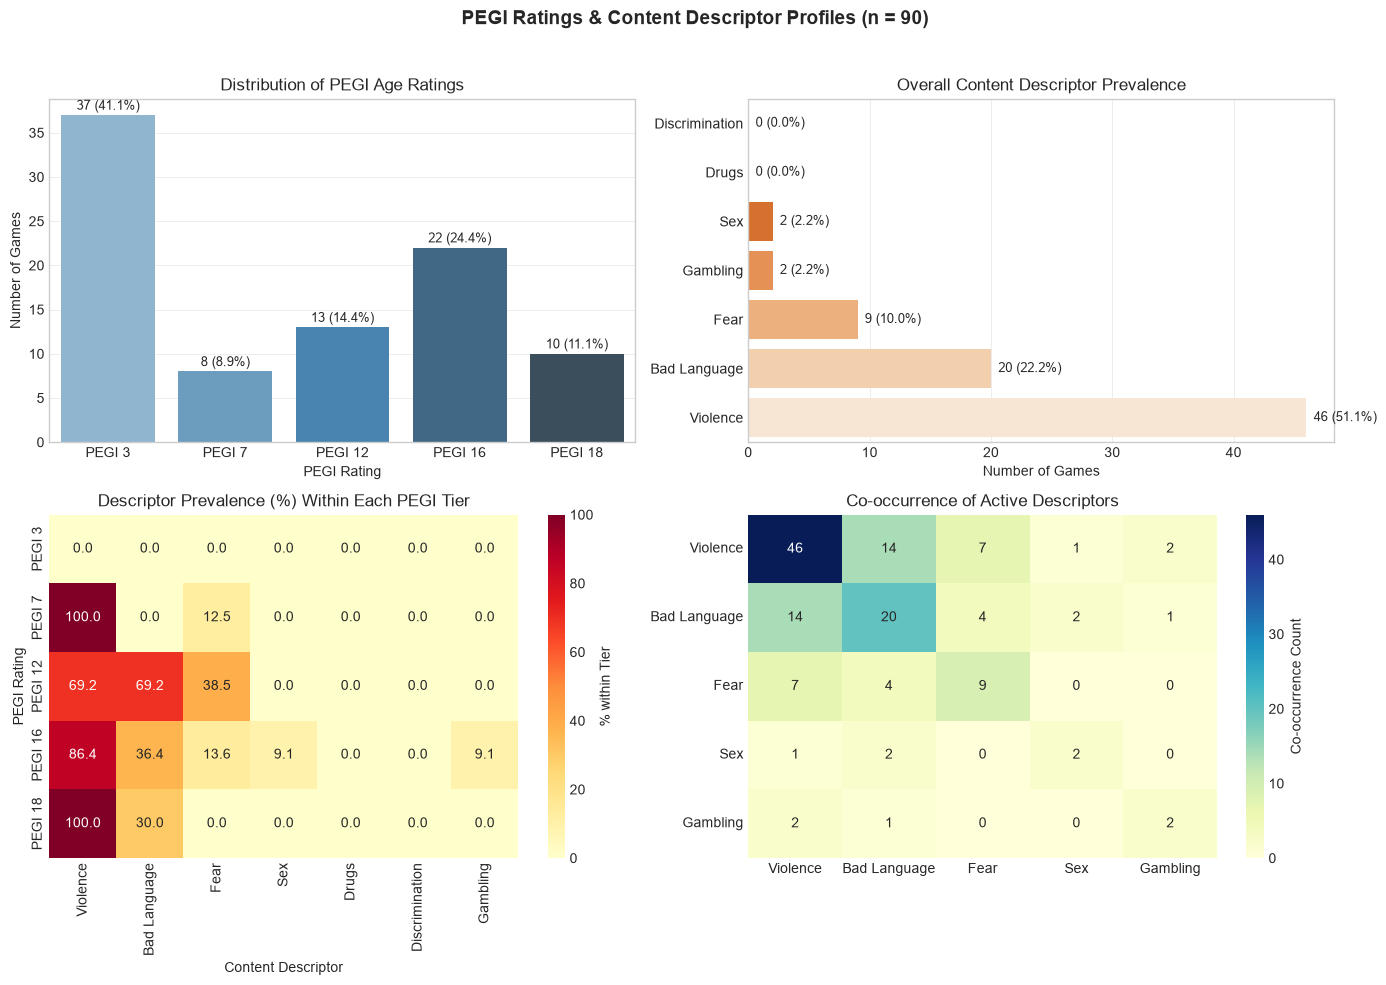

In [5]:
# Visualization: Rating distribution, descriptor prevalence, co-occurrence, and descriptor count boxplot
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
fig.suptitle(f"PEGI Ratings & Content Descriptor Profiles (n = {len(df)})", fontsize=14, fontweight="bold")

# Panel 1: Rating distribution
sns.barplot(x=rating_summary.index, y=rating_summary["count"], ax=axes[0, 0], palette="Blues_d")
axes[0, 0].set_title("Distribution of PEGI Age Ratings")
axes[0, 0].set_xlabel("PEGI Rating")
axes[0, 0].set_ylabel("Number of Games")
for i, v in enumerate(rating_summary["count"]):
    axes[0, 0].text(i, v + 0.6, f"{v} ({v/len(df)*100:.1f}%)", ha="center", fontsize=9)

# Panel 2: Descriptor prevalence across all games
d_plot = desc_overview.sort_values("count", ascending=True).copy()
d_plot.index = [c.replace("descriptor_", "").replace("_", " ").title() for c in d_plot.index]
sns.barplot(x=d_plot["count"], y=d_plot.index, ax=axes[0, 1], palette="Oranges_r")
axes[0, 1].set_title("Overall Content Descriptor Prevalence")
axes[0, 1].set_xlabel("Number of Games")
axes[0, 1].set_ylabel("")
for i, v in enumerate(d_plot["count"]):
    axes[0, 1].text(v + 0.6, i, f"{v} ({v/len(df)*100:.1f}%)", va="center", fontsize=9)

# Panel 3: Heatmap of prevalence (%) within each PEGI tier
heat_df = ct_pct.copy()
heat_df.columns = [c.replace("descriptor_", "").replace("_", " ").title() for c in heat_df.columns]
sns.heatmap(heat_df, annot=True, fmt=".1f", cmap="YlOrRd", ax=axes[1, 0], cbar_kws={"label": "% within Tier"})
axes[1, 0].set_title("Descriptor Prevalence (%) Within Each PEGI Tier")
axes[1, 0].set_xlabel("Content Descriptor")
axes[1, 0].set_ylabel("PEGI Rating")

# Panel 4: Co-occurrence of active descriptors
active_cols = [c for c in DESC_COLS if df[c].sum() > 0]
active_labels = [c.replace("descriptor_", "").replace("_", " ").title() for c in active_cols]
co_mat = df[active_cols].T.dot(df[active_cols])
co_mat.index = active_labels
co_mat.columns = active_labels
sns.heatmap(co_mat, annot=True, fmt="d", cmap="YlGnBu", ax=axes[1, 1], cbar_kws={"label": "Co-occurrence Count"})
axes[1, 1].set_title("Co-occurrence of Active Descriptors")

plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.savefig(FIGURES_DIR / "01_pegi_descriptor_profiles.png", dpi=150)
plt.show()

---
## 2. Point 2 — Relative Weight of Descriptors in Higher Age Tiers (`H2`)

We evaluate:
- Spearman rank correlations between individual binary descriptors / `num_descriptors` and `pegi_rating_code`.
- Edge cases illustrating **severity vs. count**:
  - High-tier games (`PEGI 16` / `PEGI 18`) triggered by a single severe descriptor (`num_descriptors <= 1`).
  - Intermediate-tier games (`PEGI 12`) accumulating multiple moderate descriptors (`num_descriptors >= 2`).

In [6]:
corr_rows = []
for col in DESC_COLS + ["num_descriptors"]:
    if df[col].nunique() <= 1:
        corr_rows.append({"feature": col, "spearman_rho": np.nan, "p_value": np.nan, "note": "Constant in sample"})
    else:
        rho, p_val = stats.spearmanr(df[col], df["pegi_rating_code"])
        corr_rows.append({"feature": col, "spearman_rho": round(rho, 4), "p_value": p_val, "note": ""})

corr_df = pd.DataFrame(corr_rows).sort_values(by="spearman_rho", ascending=False)
display(corr_df)

,feature,spearman_rho,p_value,note
7,num_descriptors,0.8079,6.422158e-22,
0,descriptor_violence,0.7911,1.740192e-20,
1,descriptor_bad_language,0.3994,9.652721e-05,
2,descriptor_fear,0.1501,1.578746e-01,
3,descriptor_sex,0.1459,1.699609e-01,
6,descriptor_gambling,0.1459,1.699609e-01,
4,descriptor_drugs,NaN,NaN,Constant in sample
5,descriptor_discrimination,NaN,NaN,Constant in sample


In [7]:
high_single = df[(df["pegi_rating_code"] >= 16) & (df["num_descriptors"] <= 1)][
    ["game_id", "title", "pegi_rating_label", "num_descriptors"] + DESC_COLS
]
print(f"PEGI 16/18 games with <= 1 active descriptor: {len(high_single)}")
display(high_single)

pegi12_multi = df[(df["pegi_rating_code"] == 12) & (df["num_descriptors"] >= 2)][
    ["game_id", "title", "pegi_rating_label", "num_descriptors"] + DESC_COLS
]
print(f"PEGI 12 games with >= 2 active descriptors: {len(pegi12_multi)}")
display(pegi12_multi)

PEGI 16/18 games with <= 1 active descriptor: 20


,game_id,title,pegi_rating_label,num_descriptors,descriptor_violence,descriptor_bad_language,descriptor_fear,descriptor_sex,descriptor_drugs,descriptor_discrimination,descriptor_gambling
2,GAME_0003,Active Matter,PEGI 16,1,1,0,0,0,0,0,0
3,GAME_0004,Throne and Liberty,PEGI 16,1,1,0,0,0,0,0,0
7,GAME_0008,Wolfsschanze – Operation Götterdämmerung,PEGI 16,1,1,0,0,0,0,0,0
20,GAME_0021,Crimson Desert: Charting the Unknown,PEGI 18,1,1,0,0,0,0,0,0
21,GAME_0022,Dispatch Deluxe Edition,PEGI 18,1,1,0,0,0,0,0,0
22,GAME_0023,Nightmare Reaper,PEGI 16,1,1,0,0,0,0,0,0
35,GAME_0036,Anomalith,PEGI 16,1,1,0,0,0,0,0,0
39,GAME_0040,Neon Abyss 2,PEGI 16,1,1,0,0,0,0,0,0
42,GAME_0043,Beholgar 2,PEGI 16,1,1,0,0,0,0,0,0
48,GAME_0049,Last Epoch,PEGI 16,1,1,0,0,0,0,0,0


PEGI 12 games with >= 2 active descriptors: 8


,game_id,title,pegi_rating_label,num_descriptors,descriptor_violence,descriptor_bad_language,descriptor_fear,descriptor_sex,descriptor_drugs,descriptor_discrimination,descriptor_gambling
1,GAME_0002,Strike Commander,PEGI 12,2,1,1,0,0,0,0,0
10,GAME_0011,Wing Commander 5: Prophecy Gold Edition,PEGI 12,2,0,1,1,0,0,0,0
11,GAME_0012,Privateer 2: The Darkening,PEGI 12,3,1,1,1,0,0,0,0
17,GAME_0018,Roco Kingdom,PEGI 12,2,1,0,1,0,0,0,0
31,GAME_0032,Deathless. The Hero Quest,PEGI 12,2,1,1,0,0,0,0,0
43,GAME_0044,Dave the Diver - Complete Edition,PEGI 12,2,1,1,0,0,0,0,0
45,GAME_0046,The Golden Idol Saga,PEGI 12,3,1,1,1,0,0,0,0
64,GAME_0065,Moonlighter 2: The Endless Vault,PEGI 12,2,1,1,0,0,0,0,0


---
## 3. Point 3 — Variations Across Publishers, Platforms, and Monetisation (`H3`)

We inspect how age tiers and disclosure flags vary across:
- `monetisation` (in-game purchases, loot boxes / paid random items, vs. none/unknown),
- top `publisher` entities in the dataset,
- `platforms` (exploded from multi-value `;`-delimited strings).

In [9]:
mon_ct = pd.crosstab(df["pegi_rating_label"], df["monetisation"]).reindex(PRESENT_RATINGS).fillna(0).astype(int)
print("Monetisation breakdown by PEGI tier:")
display(mon_ct)

top_publishers = df["publisher"].value_counts().head(8).index
pub_ct = (
    pd.crosstab(df[df["publisher"].isin(top_publishers)]["publisher"], df[df["publisher"].isin(top_publishers)]["pegi_rating_label"])
    .reindex(columns=PRESENT_RATINGS, fill_value=0)
)
pub_ct["Total"] = pub_ct.sum(axis=1)
pub_ct = pub_ct.sort_values("Total", ascending=False)
print("Top 8 publishers by PEGI tier:")
display(pub_ct)

platforms_exploded = (
    df[["game_id", "pegi_rating_label", "platforms"]]
    .assign(platform=df["platforms"].fillna("").str.split(" ; "))
    .explode("platform")
)
platforms_exploded["platform"] = platforms_exploded["platform"].str.strip()
platforms_exploded = platforms_exploded[platforms_exploded["platform"] != ""].reset_index(drop=True)

top_plats = platforms_exploded["platform"].value_counts().head(8).index
plat_sub = platforms_exploded[platforms_exploded["platform"].isin(top_plats)]

plat_ct = (
    pd.crosstab(plat_sub["platform"], plat_sub["pegi_rating_label"])
    .reindex(columns=PRESENT_RATINGS, fill_value=0)
)
plat_ct["Total"] = plat_ct.sum(axis=1)
plat_ct = plat_ct.sort_values("Total", ascending=False)
print("Top 8 platforms by PEGI tier:")
display(plat_ct)

Monetisation breakdown by PEGI tier:


monetisation,In-game purchases,In-game purchases ; Loot boxes / Paid random items,None / Unknown
pegi_rating_label,,,
PEGI 3,3,0,34
PEGI 7,0,0,8
PEGI 12,1,0,12
PEGI 16,9,2,11
PEGI 18,5,0,5


Top 8 publishers by PEGI tier:


pegi_rating_label,PEGI 3,PEGI 7,PEGI 12,PEGI 16,PEGI 18,Total
publisher,,,,,,
Nex Team Inc.,18,1,0,0,0,19
"Atari, Inc.",9,0,0,0,0,9
EA Swiss Sarl,0,1,4,1,0,6
Bandai Namco Entertainment Europe,0,1,0,3,0,4
Silver Lining Interactive,1,0,2,0,1,4
Tesura Games,0,0,2,2,0,4
SEGA,2,0,0,0,1,3
U&I Entertainment Limited,0,0,1,0,2,3


Top 8 platforms by PEGI tier:


pegi_rating_label,PEGI 3,PEGI 7,PEGI 12,PEGI 16,PEGI 18,Total
platform,,,,,,
PlayStation 5,7,4,5,16,8,40
PC,2,3,6,10,5,26
Nex Playground,18,1,0,0,0,19
Nintendo Switch,3,6,3,2,1,15
Nintendo Switch 2,0,4,3,3,3,13
Xbox Series X|S,1,2,0,5,4,12
ATARI,9,0,0,0,0,9
Mobile,0,0,1,1,0,2


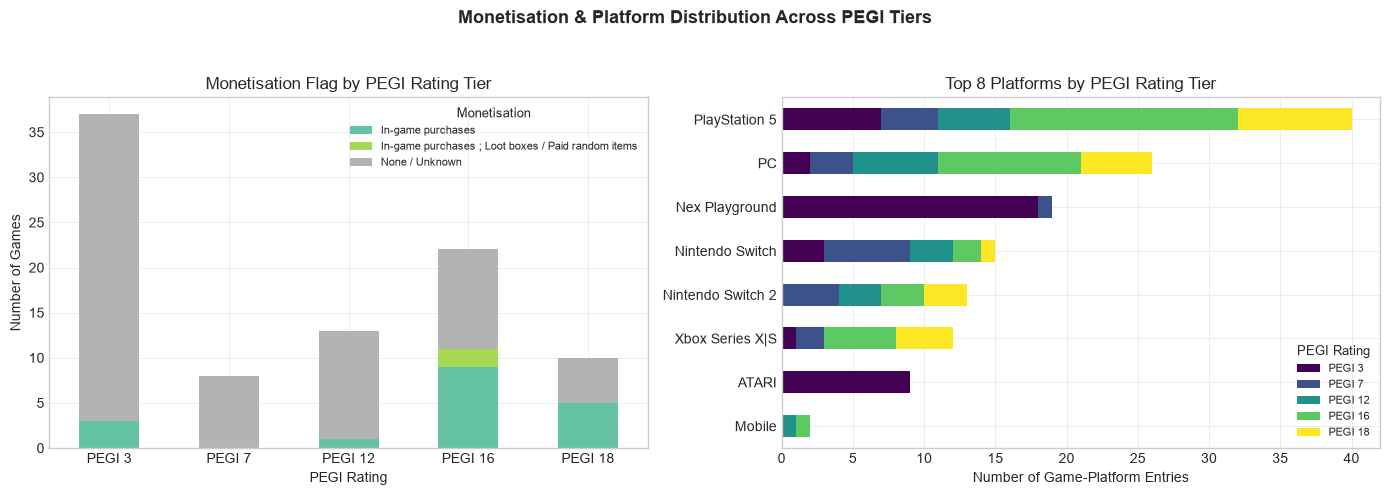

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle("Monetisation & Platform Distribution Across PEGI Tiers", fontsize=13, fontweight="bold")

mon_ct.plot(kind="bar", stacked=True, ax=axes[0], colormap="Set2")
axes[0].set_title("Monetisation Flag by PEGI Rating Tier")
axes[0].set_xlabel("PEGI Rating")
axes[0].set_ylabel("Number of Games")
axes[0].tick_params(axis="x", rotation=0)
axes[0].legend(title="Monetisation", fontsize=8, title_fontsize=9)

plat_ct.drop(columns="Total").plot(kind="barh", stacked=True, ax=axes[1], colormap="viridis")
axes[1].set_title("Top 8 Platforms by PEGI Rating Tier")
axes[1].set_xlabel("Number of Game-Platform Entries")
axes[1].set_ylabel("")
axes[1].invert_yaxis()
axes[1].legend(title="PEGI Rating", fontsize=8, title_fontsize=9)

plt.tight_layout(rect=[0, 0, 1, 0.94])
plt.savefig(FIGURES_DIR / "02_monetisation_and_platforms.png", dpi=150)
plt.show()

---
## 4. Point 4 — Refined Textual Audit: Binary Icons vs. `other_notes` / `specific_concerns` (`H1–H3` & Survey Prep `H4–H5`)

To avoid substring false positives (such as `"sex"` matching inside `"six"`), we use word-boundary regular expressions (`\b...\b`) mapped to each binary descriptor column.  
This identifies games where sensitive themes (e.g., alcohol/tobacco, simulated gambling, mild profanity, suggestive scenes) are disclosed in `other_notes` or `specific_concerns` **without** triggering the corresponding front-facing icon (`descriptor_* == 0`).

In [11]:
df["other_notes_clean"] = df["other_notes"].fillna("").str.strip()
df["specific_concerns_clean"] = df["specific_concerns"].fillna("").str.strip()
df["has_other_notes"] = (df["other_notes_clean"] != "").astype(int)

notes_coverage = (
    df.groupby("pegi_rating_label")["has_other_notes"]
    .agg(total_games="count", with_other_notes="sum", pct_with_other_notes=lambda s: round(s.mean() * 100, 1))
    .reindex(PRESENT_RATINGS)
)
print("Coverage of 'other_notes' by PEGI tier:")
display(notes_coverage)

Coverage of 'other_notes' by PEGI tier:


,total_games,with_other_notes,pct_with_other_notes
pegi_rating_label,,,
PEGI 3,37,3,8.1
PEGI 7,8,0,0.0
PEGI 12,13,10,76.9
PEGI 16,22,21,95.5
PEGI 18,10,9,90.0


In [12]:
PATTERNS = {
    "drugs_alcohol_tobacco": (
        r"\b(?:drug|drugs|alcohol|alcoholic|beer|beers|wine|vodka|whiskey|tobacco|cigarette|cigarettes|cannabis|marijuana|cocaine|heroin|opioid|vape|vaping|smoking|smoke|intoxication)\b",
        "descriptor_drugs",
    ),
    "gambling_loot": (
        r"\b(?:gambling|gamble|casino|casinos|betting|bets|loot\s*box(?:es)?|paid\s+random\s+items?|simulated\s+gambling|slot\s*machine(?:s)?|poker|roulette|wager(?:ing)?)\b",
        "descriptor_gambling",
    ),
    "sex_nudity": (
        r"\b(?:sex|sexual|sexually|nude|nudity|nipple|nipples|erotic|erotica|pornograph\w*|genital\w*|topless|provocative)\b",
        "descriptor_sex",
    ),
    "bad_language": (
        r"\b(?:bad\s+language|strong\s+language|profanity|swear(?:ing|s)?|swears|curse\s+word(?:s)?|vulgar\w*|f-word|fuck\w*|shit\w*|bitch\w*|asshole\w*|bastard\w*|piss\w*|slur\w*)\b",
        "descriptor_bad_language",
    ),
    "violence_gore": (
        r"\b(?:violen\w*|blood|bloody|gore|gory|dismember\w*|decapitat\w*|torture\w*|corpse\w*|impale\w*|murder\w*|kill\w*|shoot\w*|combat|weapon\w*)\b",
        "descriptor_violence",
    ),
    "fear_horror": (
        r"\b(?:fear|scary|horror|terrifying|nightmare\w*|disturbing|creepy|eerie|haunt\w*|jumpscare\w*|monstrous)\b",
        "descriptor_fear",
    ),
}

def audit_text_gaps(dataframe, text_col, source_label):
    records = []
    for theme, (pat, dcol) in PATTERNS.items():
        rx = re.compile(pat, flags=re.IGNORECASE)
        matched_col = dataframe[text_col].apply(
            lambda t: sorted({m.group(0).lower() for m in rx.finditer(t)})
        )
        has_match = matched_col.apply(len) > 0
        gaps = dataframe[has_match & (dataframe[dcol] == 0)]

        for idx, row in gaps.iterrows():
            excerpt = row[text_col]
            if len(excerpt) > 220:
                excerpt = excerpt[:220].rstrip() + "..."
            records.append({
                "source_field": source_label,
                "game_id": row["game_id"],
                "title": row["title"],
                "pegi_rating_label": row["pegi_rating_label"],
                "theme": theme,
                "descriptor_col": dcol,
                "matched_terms": ", ".join(matched_col.loc[idx]),
                "text_excerpt": excerpt,
            })
    return pd.DataFrame(records)

gaps_other = audit_text_gaps(df, "other_notes_clean", "other_notes")
gaps_specific = audit_text_gaps(df, "specific_concerns_clean", "specific_concerns")
gaps_all = pd.concat([gaps_other, gaps_specific], ignore_index=True)

print(f"Total icon-vs-text gap candidates detected: {len(gaps_all)}")
if not gaps_all.empty:
    display(gaps_all.groupby(["source_field", "theme", "descriptor_col"]).size().rename("candidate_count").to_frame())
    display(gaps_all)
    gaps_all.to_csv(TABLES_DIR / "01_icon_vs_text_gap_candidates.csv", index=False)

Total icon-vs-text gap candidates detected: 68


candidate_count
source_field      theme                 descriptor_col                          
other_notes       bad_language          descriptor_bad_language               14
                  drugs_alcohol_tobacco descriptor_drugs                      12
                  fear_horror           descriptor_fear                       14
                  gambling_loot         descriptor_gambling                    1
                  sex_nudity            descriptor_sex                        11
                  violence_gore         descriptor_violence                    5
specific_concerns drugs_alcohol_tobacco descriptor_drugs                       3
                  violence_gore         descriptor_violence                    8

,source_field,game_id,title,pegi_rating_label,theme,descriptor_col,matched_terms,text_excerpt
0,other_notes,GAME_0002,Strike Commander,PEGI 12,drugs_alcohol_tobacco,descriptor_drugs,"alcohol, cigarettes, smoking",Some NPCs are seen consuming alcohol and smoking cigarettes. The player cannot interact with these substances. There are some posters on...
1,other_notes,GAME_0011,Wing Commander 5: Prophecy Gold Edition,PEGI 12,drugs_alcohol_tobacco,descriptor_drugs,"alcohol, alcoholic","The game contains implied violence. During space combat, the player must shoot at and destroy enemy spaceships. A large, colourful explo..."
2,other_notes,GAME_0021,Crimson Desert: Charting the Unknown,PEGI 18,drugs_alcohol_tobacco,descriptor_drugs,alcohol,"The base game and this DLC also contain the use of strong language, including 'fuck'. Prominent use of alcohol is found in the base game..."
3,other_notes,GAME_0028,Agefield High: Rock the School,PEGI 16,drugs_alcohol_tobacco,descriptor_drugs,"alcohol, beer, drug, drugs","Alcohol is referenced throughout the game with red cups and beer bottles seen littering a house during a party scene. At one point, the ..."
4,other_notes,GAME_0044,Dave the Diver - Complete Edition,PEGI 12,drugs_alcohol_tobacco,descriptor_drugs,"alcohol, alcoholic, beer, beers","While serving customers in the sushi bar, the player is asked to pour beers. The player is not able to consume the alcohol themselves. B..."
...,...,...,...,...,...,...,...,...
63,specific_concerns,GAME_0041,Backrooms Level X,PEGI 12,violence_gore,descriptor_violence,corpse,This game contains moderate horror sequences and disturbing images. The player will often encounter creatures in the rooms who will begi...
64,specific_concerns,GAME_0048,Freefall Racers,PEGI 3,violence_gore,descriptor_violence,"violence, weapon",This game features very mild forms of violence. Getting hit by a weapon power-up results in characters slowing down and a brief hit anim...
65,specific_concerns,GAME_0085,GALAX,PEGI 3,violence_gore,descriptor_violence,violence,"This game contains depictions of very mild violence in a child-like, pixelated or abstract setting. When enemy ships (shaped like bugs) ..."
66,specific_concerns,GAME_0086,Arrow Party,PEGI 3,violence_gore,descriptor_violence,"shoot, shooting","In most games players shoot at objects such as balloons, bottles, dynamite and apples. In one mini-game, players must defeat a giant rob..."


---
## 5. Point 5 — Sample Limitations & Methodological Guardrails

Before moving to predictive modeling (`02_predictive_modeling.ipynb`) or generalizing findings, we explicitly audit completeness, structural unknowns, and sample-composition constraints.

In [13]:
audit_rows = []
for col in df_raw.columns:
    empty_cnt = int(df_raw[col].isna().sum() + (df_raw[col].astype(str).str.strip() == "").sum())
    unk_cnt = int((df_raw[col].astype(str).str.strip().str.lower() == "unknown").sum())
    none_unk_cnt = int((df_raw[col].astype(str).str.strip() == "None / Unknown").sum())
    audit_rows.append({
        "column": col,
        "dtype": str(df_raw[col].dtype),
        "empty_or_nan": empty_cnt,
        "unknown_str": unk_cnt,
        "none_or_unknown_str": none_unk_cnt,
        "usable_non_empty_pct": round((1 - (empty_cnt + unk_cnt) / len(df_raw)) * 100, 1),
    })

completeness_df = pd.DataFrame(audit_rows)
display(completeness_df[completeness_df["usable_non_empty_pct"] < 100.0])

,column,dtype,empty_or_nan,unknown_str,none_or_unknown_str,usable_non_empty_pct
13,consumer_advice,str,12,0,0,86.7
14,game_summary,str,12,0,0,86.7
15,specific_concerns,str,12,0,0,86.7
16,other_notes,str,47,0,0,47.8
18,genres,str,0,90,0,0.0
20,developer,str,0,90,0,0.0
23,online_play,str,0,85,0,5.6


### Key Methodological Guardrails
1. **Sample Size & Selection Bias (`n = 90`):** Extracted from initial PEGI search pages constrained by pagination limits; heavily weighted toward specific publishers (e.g., *Nex Team Inc.*, *Atari, Inc.*), inflating `PEGI 3` (`41.1%`).
2. **Zero-Variance Descriptors in Current Batch:** `descriptor_drugs` and `descriptor_discrimination` have `0` positive binary flags in this batch, requiring dataset expansion before multi-class modeling relies on those features.
3. **Metadata Enrichments Needed:** `genres` (`100% Unknown`), `developer` (`100% Unknown`), and `online_play` (`94.4% Unknown`) reflect parser defaults where structured fields were absent from raw PEGI search cards.
4. **Descriptive Scope Only:** All patterns and correlations here describe PEGI classification metadata and disclosure structure; they do not measure psychological or behavioral effects on children.